# Movilidad urbana y desarrollo económico en ciudades de América Latina

**TripleTen Data Analyst Bootcamp · Proyecto 5 · 2026** · Autor: Luis Guillermo Barrera Barrios

Datos: TomTom Traffic Index y OECD City Economy (provistos por el bootcamp). Para ejecutar el notebook, coloca `tomtom_traffic.csv` y `oecd_city_economy.csv` en una carpeta `datasets/`.

## Introducción

Como analista de datos, tu objetivo es **evaluar cómo la movilidad urbana se relaciona con la productividad económica en las principales ciudades latinoamericanas**. 
Para ello trabajarás con datos reales de TomTom Traffic Index y OECD Cities, que deberás limpiar, combinar y analizar para identificar en qué ciudades conviene invertir en infraestructura de transporte.

## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de ambos datasets**.
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯Objetivo:**
Importar las librerías necesarias, cargar los archivos CSV en DataFrames y realizar una revisión preliminar para entender su contenido.

**Instrucciones:**
- Importa las librerías `pandas`, `numpy`, `seaborn` y `matplotlib.pyplot`.
- Carga los archivos usando `pd.read_csv()`:
  - `'/datasets/tomtom_traffic.csv'`
  - `/datasets/oecd_city_economy.csv` `.
- Guarda los DataFrames en las variables `traffic` y `eco`.
- Muestra las primeras 5 filas de cada DataFrame.


In [1]:
# importar librerías
# Importar librerías
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
# Cargar archivos
traffic = pd.read_csv('datasets/tomtom_traffic.csv')
eco = pd.read_csv('datasets/oecd_city_economy.csv')

In [3]:
# Mostrar las primeras 5 filas de traffic
print("TRAFFIC - Primeras 5 filas:")
traffic.head()

TRAFFIC - Primeras 5 filas:


,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232
3,ARE,abu-dhabi,2025-01-13 01:46:30.001,8.2,2.0,4.1,2.0,2.0,2025-01-06 01:46:30.000,7.723808,7.899046,-0.175238
4,ARE,abu-dhabi,2025-01-13 00:01:30.000,1.1,1.0,0.2,1.0,1.0,2025-01-06 00:01:30.000,8.336363,8.604379,-0.268016


In [4]:
# Mostrar las primeras 5 filas de eco
print("ECO - Primeras 5 filas:")
eco.head()

ECO - Primeras 5 filas:


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"
3,2023,brasilia,Brazil,"15.999,00",8.3%,"13,50","4,70"
4,2023,salvador,Brazil,"8.761,00",13.1%,"16,00","3,90"



---

## 🧩Paso 2: Explorar, limpiar y preparar los datos

Antes de combinar los datasets, inspecciona su estructura, tipos de datos, columnas y valores faltantes.
Anota las columnas que necesiten limpieza y luego estandariza los nombres de columnas.

### 2.1 Explorar la estructura y tipos de datos

**🎯Objetivo:**
Identificar columnas con tipos incorrectos, distribución y nulos, anotar las columnas que requieren conversión.

**Instrucciones:**

- Usa `.info()` para conocer la estructura de ambos DataFrames.
- Muestra los primeros 3 renglones de cada DF.
- Identifica si los detalles de cada DF estan bien o si requieren correcciones y escribe tus conclusiones en el bloque Markdown.
  - ¿Hay columnas que requieren conversión?¿ Cuáles son? ¿Que tipo de dato ienen y cuál deberían de tener?
  - ¿Hay datos ausentes en alguna columna?


In [5]:
# Examinar la estructura de traffic
# Examinar la estructura de traffic
print("="*80)
print("ESTRUCTURA DE TRAFFIC")
print("="*80)
traffic.info()
print("\nPrimeras 3 filas:")
traffic.head(3)

ESTRUCTURA DE TRAFFIC
<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype  
---  ------                          --------------    -----  
 0   Country                         1004464 non-null  str    
 1   City                            1004464 non-null  str    
 2   UpdateTimeUTC                   1004464 non-null  str    
 3   JamsDelay                       1004464 non-null  float64
 4   TrafficIndexLive                1004464 non-null  float64
 5   JamsLengthInKms                 1004464 non-null  float64
 6   JamsCount                       1004464 non-null  float64
 7   TrafficIndexWeekAgo             1004464 non-null  float64
 8   UpdateTimeUTCWeekAgo            1004464 non-null  str    
 9   TravelTimeLivePer10KmsMins      1004464 non-null  float64
 10  TravelTimeHistoricPer10KmsMins  1004464 non-null  float64
 11  MinsDelay                       1004464 non-null  fl

,Country,City,UpdateTimeUTC,JamsDelay,TrafficIndexLive,JamsLengthInKms,JamsCount,TrafficIndexWeekAgo,UpdateTimeUTCWeekAgo,TravelTimeLivePer10KmsMins,TravelTimeHistoricPer10KmsMins,MinsDelay
0,ARE,abu-dhabi,2025-01-13 04:01:30.001,650.7,36.0,109.1,162.0,30.0,2025-01-06 04:01:30.000,11.614767,10.265330,1.349437
1,ARE,abu-dhabi,2025-01-13 03:46:00.000,540.4,30.0,101.4,136.0,27.0,2025-01-06 03:46:30.001,11.003180,10.031544,0.971635
2,ARE,abu-dhabi,2025-01-13 02:46:30.000,71.8,7.0,18.9,23.0,6.0,2025-01-06 02:46:30.000,8.196278,8.196510,-0.000232


**Observaciones sobre `traffic`:**
- 1,004,464 filas y 12 columnas, sin valores nulos.
- `UpdateTimeUTC` y `UpdateTimeUTCWeekAgo` están como texto (`str`) y deben convertirse a fecha (`datetime`).
- El archivo incluye ciudades de todo el mundo, no solo de América Latina; el cruce con `eco` deja únicamente las latinoamericanas.

In [6]:

# Examinar la estructura de eco
print("="*80)
print("ESTRUCTURA DE ECO")
print("="*80)
eco.info()
print("\nPrimeras 3 filas:")
eco.head(3)

ESTRUCTURA DE ECO
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Year             30 non-null     int64
 1   City             30 non-null     str  
 2   Country          30 non-null     str  
 3   City GDP/capita  30 non-null     str  
 4   Unemployment %   30 non-null     str  
 5   PM2.5 (μg/m³)    30 non-null     str  
 6   Population (M)   30 non-null     str  
dtypes: int64(1), str(6)
memory usage: 1.8 KB

Primeras 3 filas:


,Year,City,Country,City GDP/capita,Unemployment %,PM2.5 (μg/m³),Population (M)
0,2023,buenos-aires,Argentina,"15.782,00",6.2%,"15,2","15,30"
1,2023,sao-paulo,Brazil,"14.475,00",9.1%,"29,50","22,50"
2,2023,rio-de-janeiro,Brazil,"13.142,00",9.8%,"19,10","13,60"


**Observaciones sobre `eco`:**
- 30 filas = 15 ciudades × 2 años (2023 y 2024), 7 columnas, sin nulos.
- `City GDP/capita`, `Unemployment %`, `PM2.5 (μg/m³)` y `Population (M)` están como texto con separador de miles (punto), coma decimal o símbolo `%`; hay que limpiarlas antes de convertirlas a número.

### 2.2 Renombrar columnas

**🎯Objetivo:**
Estandarizar los nombres de columnas para evitar errores y facilitar la unión de los datasets.

**Instrucciones:**

- Cambia los nombres de las columnas para que tengan el formato `snake_case`.
    - `Country` → `country`
    - `UpdateTimeUTC` → `update_time_utc`
- Verifica que los cambios se hayan aplicado correctamente usando `.columns`.


In [7]:

# Estandarizar los nombres de las columnas de traffic
traffic.columns = traffic.columns.str.lower().str.replace(' ', '_')

# Verificar cambios
print("Columnas de traffic después de renombrar:")
print(traffic.columns.tolist())

Columnas de traffic después de renombrar:
['country', 'city', 'updatetimeutc', 'jamsdelay', 'trafficindexlive', 'jamslengthinkms', 'jamscount', 'trafficindexweekago', 'updatetimeutcweekago', 'traveltimeliveper10kmsmins', 'traveltimehistoricper10kmsmins', 'minsdelay']


In [8]:

# Estandarizar los nombres de las columnas de eco
eco.columns = eco.columns.str.lower().str.replace(' ', '_')

# Verificar cambios
print("\nColumnas de eco después de renombrar:")
print(eco.columns.tolist())


Columnas de eco después de renombrar:
['year', 'city', 'country', 'city_gdp/capita', 'unemployment_%', 'pm2.5_(μg/m³)', 'population_(m)']



### 2.3 Corregir formatos numéricos y de fecha

**🎯Objetivo:**
Asegurar que las columnas de fechas y valores numéricos estén en formatos correctos para permitir análisis, cálculos y comparaciones precisas.

**Instrucciones:**

- Convierte las columnas de fecha de `traffic` a formato `datetime`. Haz el cambio a prueba de errores.
- En el dataset `eco`, limpia los valores numéricos:
    - En `city_gdp_capita`: elimina separadores de miles (`.`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `unemployment_pct`: elimina el símbolo de porcentaje (`%`) y reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
    - En `population_m`: reemplaza las comas (`','`) por puntos (`'.'`) antes de convertir a tipo `float`.
- Finalmente, crea una nueva columna llamada `population` multiplicando `population_m` por 1,000,000 para obtener la población total.


In [9]:
# Convertir las columnas de fecha a tipo datetime
traffic['updatetimeutc'] = pd.to_datetime(traffic['updatetimeutc'], errors='coerce')
traffic['updatetimeutcweekago'] = pd.to_datetime(traffic['updatetimeutcweekago'], errors='coerce')

# Verificar cambio
print("TRAFFIC después de convertir fechas:")
traffic.info()

print("\n" + "="*80)

TRAFFIC después de convertir fechas:
<class 'pandas.DataFrame'>
RangeIndex: 1004464 entries, 0 to 1004463
Data columns (total 12 columns):
 #   Column                          Non-Null Count    Dtype         
---  ------                          --------------    -----         
 0   country                         1004464 non-null  str           
 1   city                            1004464 non-null  str           
 2   updatetimeutc                   1004464 non-null  datetime64[us]
 3   jamsdelay                       1004464 non-null  float64       
 4   trafficindexlive                1004464 non-null  float64       
 5   jamslengthinkms                 1004464 non-null  float64       
 6   jamscount                       1004464 non-null  float64       
 7   trafficindexweekago             1004464 non-null  float64       
 8   updatetimeutcweekago            1004464 non-null  datetime64[us]
 9   traveltimeliveper10kmsmins      1004464 non-null  float64       
 10  traveltimehistor

In [10]:

# Limpiar y convertir columnas numéricas en eco
eco['city_gdp/capita'] = (eco['city_gdp/capita']
                          .astype(str)
                          .str.replace('.', '', regex=False)
                          .str.replace(',', '.', regex=False)
                          .astype(float))

eco['unemployment_%'] = (eco['unemployment_%']
                         .astype(str)
                         .str.replace('%', '', regex=False)
                         .str.replace(',', '.', regex=False)
                         .astype(float))

eco['population_(m)'] = (eco['population_(m)']
                         .astype(str)
                         .str.replace(',', '.', regex=False)
                         .astype(float))

eco['pm2.5_(μg/m³)'] = (eco['pm2.5_(μg/m³)']
                        .astype(str)
                        .str.replace(',', '.', regex=False)
                        .astype(float))

# Calcular población total en unidades absolutas
eco['population'] = eco['population_(m)'] * 1_000_000

# Verificar cambios
print("ECO después de limpiar números:")
eco.info()
print("\nPrimeras 3 filas de eco después de limpieza:")
eco.head(3)

ECO después de limpiar números:
<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   year             30 non-null     int64  
 1   city             30 non-null     str    
 2   country          30 non-null     str    
 3   city_gdp/capita  30 non-null     float64
 4   unemployment_%   30 non-null     float64
 5   pm2.5_(μg/m³)    30 non-null     float64
 6   population_(m)   30 non-null     float64
 7   population       30 non-null     float64
dtypes: float64(5), int64(1), str(2)
memory usage: 2.0 KB

Primeras 3 filas de eco después de limpieza:


,year,city,country,city_gdp/capita,unemployment_%,pm2.5_(μg/m³),population_(m),population
0,2023,buenos-aires,Argentina,15782.0,6.2,15.2,15.3,15300000.0
1,2023,sao-paulo,Brazil,14475.0,9.1,29.5,22.5,22500000.0
2,2023,rio-de-janeiro,Brazil,13142.0,9.8,19.1,13.6,13600000.0



---

## 🧩Paso 3: Extraer año y filtrar

Extraer el año permite filtrar la información y trabajar solo con el período más reciente y relevante.

### 3.1 Extraer columna año y filtrar 2024

**🎯Objetivo**
Identificar el año de cada registro y mantener solo los registros del 2024.

**Intrucciones**

- Como el DataFrame `traffic` no tiene una columna de año, utiliza el atributo `.dt.year` sobre su columna de fecha para crear una nueva columna llamada `year`.
- Filtra las filas donde el año sea **2024**.
- Utiliza `.copy()` para crear dos nuevos DataFrames (`traffic_2024` y `eco_2024`) para evitar modificar el dataset original.

In [11]:

# Extraer el año de las fechas en updatetimeutc
traffic['year'] = traffic['updatetimeutc'].dt.year

# Verificar cambio
print("TRAFFIC con columna 'year':")
print(traffic.head(3))

print("\n" + "="*80)

TRAFFIC con columna 'year':
  country       city           updatetimeutc  jamsdelay  trafficindexlive  \
0     ARE  abu-dhabi 2025-01-13 04:01:30.001      650.7              36.0   
1     ARE  abu-dhabi 2025-01-13 03:46:00.000      540.4              30.0   
2     ARE  abu-dhabi 2025-01-13 02:46:30.000       71.8               7.0   

   jamslengthinkms  jamscount  trafficindexweekago    updatetimeutcweekago  \
0            109.1      162.0                 30.0 2025-01-06 04:01:30.000   
1            101.4      136.0                 27.0 2025-01-06 03:46:30.001   
2             18.9       23.0                  6.0 2025-01-06 02:46:30.000   

   traveltimeliveper10kmsmins  traveltimehistoricper10kmsmins  minsdelay  year  
0                   11.614767                       10.265330   1.349437  2025  
1                   11.003180                       10.031544   0.971635  2025  
2                    8.196278                        8.196510  -0.000232  2025  



In [12]:

# Filtrar los registros del año 2024
traffic_2024 = traffic[traffic['year'] == 2024].copy()
# Corrección: el dataset económico trae 2023 y 2024; se conserva solo 2024 para evitar duplicar cada ciudad
eco_2024 = eco[eco['year'] == 2024].copy()

print(f"\nTraffic 2024: {traffic_2024.shape[0]} filas")
print(f"Eco 2024: {eco_2024.shape[0]} filas")

# Revisar dataframes nuevos
print("\nTraffic 2024 - Primeras filas:")
print(traffic_2024.head())

print("\nEco 2024 - Primeras filas:")
print(eco_2024.head())


Traffic 2024: 886779 filas
Eco 2024: 15 filas

Traffic 2024 - Primeras filas:
    country       city           updatetimeutc  jamsdelay  trafficindexlive  \
302     ARE  abu-dhabi 2024-12-31 23:01:30.000       12.9               5.0   
303     ARE  abu-dhabi 2024-12-31 22:01:30.000      136.0              21.0   
304     ARE  abu-dhabi 2024-12-31 21:16:30.000      455.2              31.0   
305     ARE  abu-dhabi 2024-12-31 20:01:00.001      399.4              27.0   
306     ARE  abu-dhabi 2024-12-31 19:46:00.000      366.4              28.0   

     jamslengthinkms  jamscount  trafficindexweekago    updatetimeutcweekago  \
302              2.5        5.0                  2.0 2024-12-24 23:01:30.001   
303             20.6       32.0                  3.0 2024-12-24 22:01:30.000   
304             40.4       72.0                  4.0 2024-12-24 21:01:30.000   
305             38.0       75.0                  6.0 2024-12-24 20:01:30.001   
306             39.8       82.0               


---

## 🧩Paso 4: Analizar y resumir datos de movilidad

Como el dataset de tráfico contiene **múltiples registros por ciudad**. En esta parte, calcularás los promedios anuales por ciudad para simplificar el análisis y obtener una visión más clara de las tendencias generales.

### 4.1 Calcular promedios de tráfico por ciudad

**🎯Objetivo:**
Obtener una vista consolidada del tráfico promedio por ciudad y año, para analizar patrones generales sin depender de datos diarios.

**Instrucciones**

- Agrupa los datos por `city`, `country` y `year`.
- Calcula el promedio **solo de las métricas de tráfico más relevantes**: como `jams_delay`, `traffic_index_live`, `jams_length_kms`, `jams_count`, `mins_delay`, y tiempos de viaje (`travel_time_live_per_10kms_mins` y `travel_time_hist_per_10kms_mins`).
- Guarda el resultado como `traffic_city_year_2024`, mantén las columnas como variables (no índices).


In [13]:
# Calcular los promedios de tráfico por ciudad, país y año
traffic_city_year_2024 = (traffic_2024
    .groupby(['city', 'country', 'year'])
    .agg({
        'jamsdelay': 'mean',
        'trafficindexlive': 'mean',
        'jamslengthinkms': 'mean',
        'jamscount': 'mean',
        'minsdelay': 'mean',
        'traveltimeliveper10kmsmins': 'mean',
        'traveltimehistoricper10kmsmins': 'mean'
    })
    .reset_index()
)

# Mostrar resultado
print("Traffic agregado por ciudad, país y año:")
print(traffic_city_year_2024.head())

print(f"\nTotal de ciudades: {traffic_city_year_2024.shape[0]}")

Traffic agregado por ciudad, país y año:
        city country  year   jamsdelay  trafficindexlive  jamslengthinkms  \
0   a-coruna     ESP  2024   17.935187         15.259774         2.198002   
1     aachen     DEU  2024   26.732141         20.960314         3.892586   
2     aarhus     DNK  2024   21.200616         16.575891         2.736736   
3  abu-dhabi     ARE  2024  171.157315         13.902028        24.507380   
4      adana     TUR  2024   83.864761         22.541040        11.827331   

   jamscount  minsdelay  traveltimeliveper10kmsmins  \
0   4.934405   0.774172                   16.267977   
1   6.601832   0.792968                   13.397861   
2   6.109987   0.495276                   15.219292   
3  47.268019   0.139764                    9.829092   
4  23.754620   1.129749                   15.879694   

   traveltimehistoricper10kmsmins  
0                       15.493804  
1                       12.604894  
2                       14.724016  
3                    

In [14]:
# Encontrar la ciudad con mayor tiempo promedio de tráfico
print("="*80)
print("CIUDAD CON MAYOR JAMS_DELAY (CONGESTIÓN)")
print("="*80)

ciudad_mayor_trafico = traffic_city_year_2024.sort_values("jamsdelay", ascending=False)
print(ciudad_mayor_trafico.head(10))

print(f"\n📍 La ciudad con el mayor tiempo promedio de tráfico es: "
      f"{ciudad_mayor_trafico.iloc[0]['city'].upper()}, "
      f"{ciudad_mayor_trafico.iloc[0]['country']}")
print(f"   JamsDelay (retraso): {ciudad_mayor_trafico.iloc[0]['jamsdelay']:.2f} minutos")

CIUDAD CON MAYOR JAMS_DELAY (CONGESTIÓN)
            city country  year    jamsdelay  trafficindexlive  \
221  mexico-city     MEX  2024  2833.057892         34.218190   
352        tokyo     JPN  2024  2152.574357         36.805059   
246     new-york     USA  2024  2133.400000         28.210388   
200       london     GBR  2024  2050.703662         29.230166   
211       manila     PHL  2024  1741.493381         66.129402   
321    sao-paulo     BRA  2024  1729.189270         26.877932   
156     istanbul     TUR  2024  1660.789019         45.614786   
159      jakarta     IDN  2024  1379.037135         30.419242   
268        paris     FRA  2024  1320.746822         29.313446   
201  los-angeles     USA  2024  1277.210458         30.446623   

     jamslengthinkms   jamscount  minsdelay  traveltimeliveper10kmsmins  \
221       389.239265  594.969392   1.855542                   21.809092   
352       373.069734  518.809420   0.698152                   22.443778   
246       398.2278

**Resultado:** la ciudad con mayor `JamsDelay` promedio en 2024 es **Ciudad de México (≈ 2,833)**, la más alta de todo el dataset. Entre las ciudades latinoamericanas le siguen **São Paulo (≈ 1,729)** y **Bogotá (≈ 1,142)**.


---

## 🧩Paso 5: Unir movilidad y economía

Combinar datasets te permite analizar cómo se relacionan los indicadores económicos con los de movilidad.

### 5.1 Unir tráfico (tabla principal) con indicadores económicos

**🎯Objetivo:**
Combinar la información de tráfico y economía en un solo DataFrame para analizar cómo las condiciones económicas se relacionan con la movilidad urbana.

**Instrucciones**
- Selecciona solo las **columnas relevantes** de cada dataset (por ejemplo, variables clave de tráfico y de economía).
- Usa `.copy()` al crear subconjuntos para evitar modificar el dataset original.
- Une ambos DataFrames y define como **claves de unión** a `city` y `year`.
- Mantén solo las ciudades y años presentes en ambos datasets.
- Guarda el resultado en una nueva variable llamada `merged` y muestra las primeras 5 filas.


In [15]:

# Seleccionar columnas clave de tráfico y economía
left_cols = ['city', 'country', 'year', 'jamsdelay', 'trafficindexlive',
             'jamslengthinkms', 'jamscount', 'minsdelay',
             'traveltimeliveper10kmsmins', 'traveltimehistoricper10kmsmins']

right_cols = ['city', 'city_gdp/capita', 'unemployment_%', 'pm2.5_(μg/m³)', 'population']

# Crear datasets reducidos con .copy()
traffic_2024_small = traffic_city_year_2024[left_cols].copy()
eco_2024_small = eco_2024[right_cols].copy()

print("Traffic reducido:")
print(traffic_2024_small.head())

print("\nEco reducido:")
print(eco_2024_small.head())

print("\n" + "="*80)

# Unir datasets por city (INNER JOIN para mantener solo ciudades en ambos)
merged = pd.merge(
    traffic_2024_small,
    eco_2024_small,
    on='city',
    how='inner'
)

print(f"\n✅ Merge completado: {merged.shape[0]} ciudades × {merged.shape[1]} columnas")

# Mostrar las primeras 5 filas
print("\nPrimeras 5 filas del dataset unificado:")
merged.head()

Traffic reducido:
        city country  year   jamsdelay  trafficindexlive  jamslengthinkms  \
0   a-coruna     ESP  2024   17.935187         15.259774         2.198002   
1     aachen     DEU  2024   26.732141         20.960314         3.892586   
2     aarhus     DNK  2024   21.200616         16.575891         2.736736   
3  abu-dhabi     ARE  2024  171.157315         13.902028        24.507380   
4      adana     TUR  2024   83.864761         22.541040        11.827331   

   jamscount  minsdelay  traveltimeliveper10kmsmins  \
0   4.934405   0.774172                   16.267977   
1   6.601832   0.792968                   13.397861   
2   6.109987   0.495276                   15.219292   
3  47.268019   0.139764                    9.829092   
4  23.754620   1.129749                   15.879694   

   traveltimehistoricper10kmsmins  
0                       15.493804  
1                       12.604894  
2                       14.724016  
3                        9.689328  
4       

,city,country,year,jamsdelay,trafficindexlive,jamslengthinkms,jamscount,minsdelay,traveltimeliveper10kmsmins,traveltimehistoricper10kmsmins,city_gdp/capita,unemployment_%,pm2.5_(μg/m³),population
0,belo-horizonte,BRA,2024,263.047879,19.428946,44.038129,68.805422,0.487228,18.304538,17.817311,11124.0,9.5,16.8,6100000.0
1,bogota,COL,2024,1141.552364,37.614273,140.893564,230.566550,1.699628,24.992185,23.292557,11442.0,10.0,17.6,11300000.0
2,brasilia,BRA,2024,101.576326,11.258220,18.337133,27.280140,0.193442,13.338658,13.145216,16251.0,7.8,12.8,4800000.0
3,buenos-aires,ARG,2024,571.089593,17.756012,100.287844,137.359860,0.416566,17.907916,17.491349,18117.0,7.2,14.5,15400000.0
4,curitiba,BRA,2024,183.469274,14.954545,30.050044,46.898164,0.139965,17.258700,17.118736,12381.0,8.2,13.5,3700000.0



---

## 🧩Paso 6: Visualización y análisis de relaciones

Ahora que tienes un dataset limpio y unificado, es momento de **visualizar patrones**.
Los gráficos te ayudarán a entender cómo se relacionan las variables económicas con las de movilidad urbana.

### 6.1 Visualizar relaciones entre economía y tráfico

**🎯Objetivo:**
Analizar visualmente la distribución y la relación entre indicadores de tráfico y economía en 2024, para identificar posibles patrones o tendencias generales entre ambas variables.

**Instrucciones**
- Usa las librerías `seaborn` y `matplotlib.pyplot` para generar los gráficos.
- Visualiza la distribución del **tráfico** (`jams_delay`) mediante:
    - **Boxplot** → para observar la media, mediana y detectar valores atípicos.
- Visualiza la distribución de la **economía** (`city_gdp_capita`) mediante:
    - **Histograma** → para analizar la forma de la distribución y el valor promedio del PIB per cápita.
- Finalmente, **compara ambas variables**, para observar si existe alguna relación entre ellas, haciendo un solo gráfico de barras donde aparezcan ambos indicadores.
- Recuerda agregar título y etiquetas a los ejes de tus gráficos.
- Observa y comenta los patrones, valores extremos o posibles relaciones que identifiques.

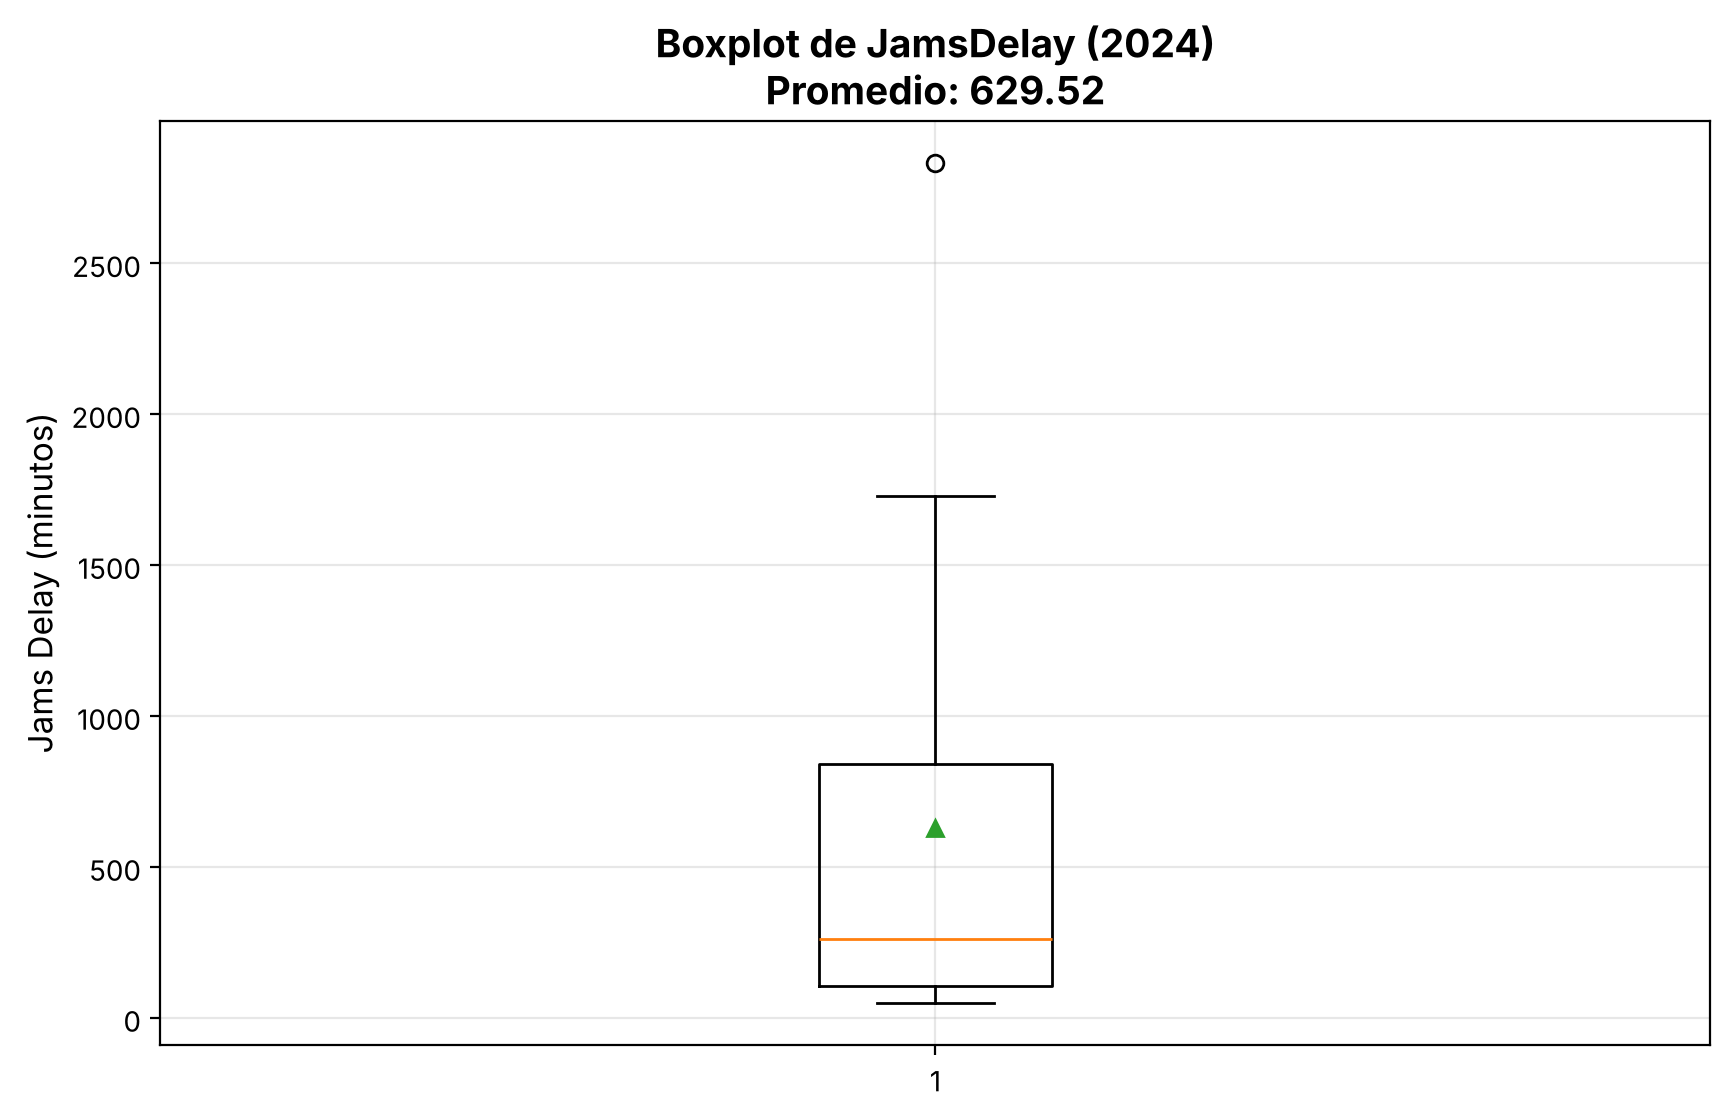

Estadísticas de JamsDelay:
count      15.000000
mean      629.517204
std       783.063726
min        50.201092
25%       107.165938
50%       263.047879
75%       841.079053
max      2833.057892
Name: jamsdelay, dtype: float64


In [16]:

# Crear boxplot para observar el comportamiento de los minutos de congestión JamsDelay
fig, ax = plt.subplots(figsize=(10, 6))

ax.boxplot(merged['jamsdelay'], showmeans=True)

# Obtener promedio para mostrarlo en título
mean_value = merged['jamsdelay'].mean()
plt.title(f'Boxplot de JamsDelay (2024)\nPromedio: {mean_value:.2f}', fontsize=14, fontweight='bold')
plt.ylabel('Jams Delay (minutos)', fontsize=12)
plt.grid(True, alpha=0.3)

plt.show()

print(f"Estadísticas de JamsDelay:")
print(merged['jamsdelay'].describe())

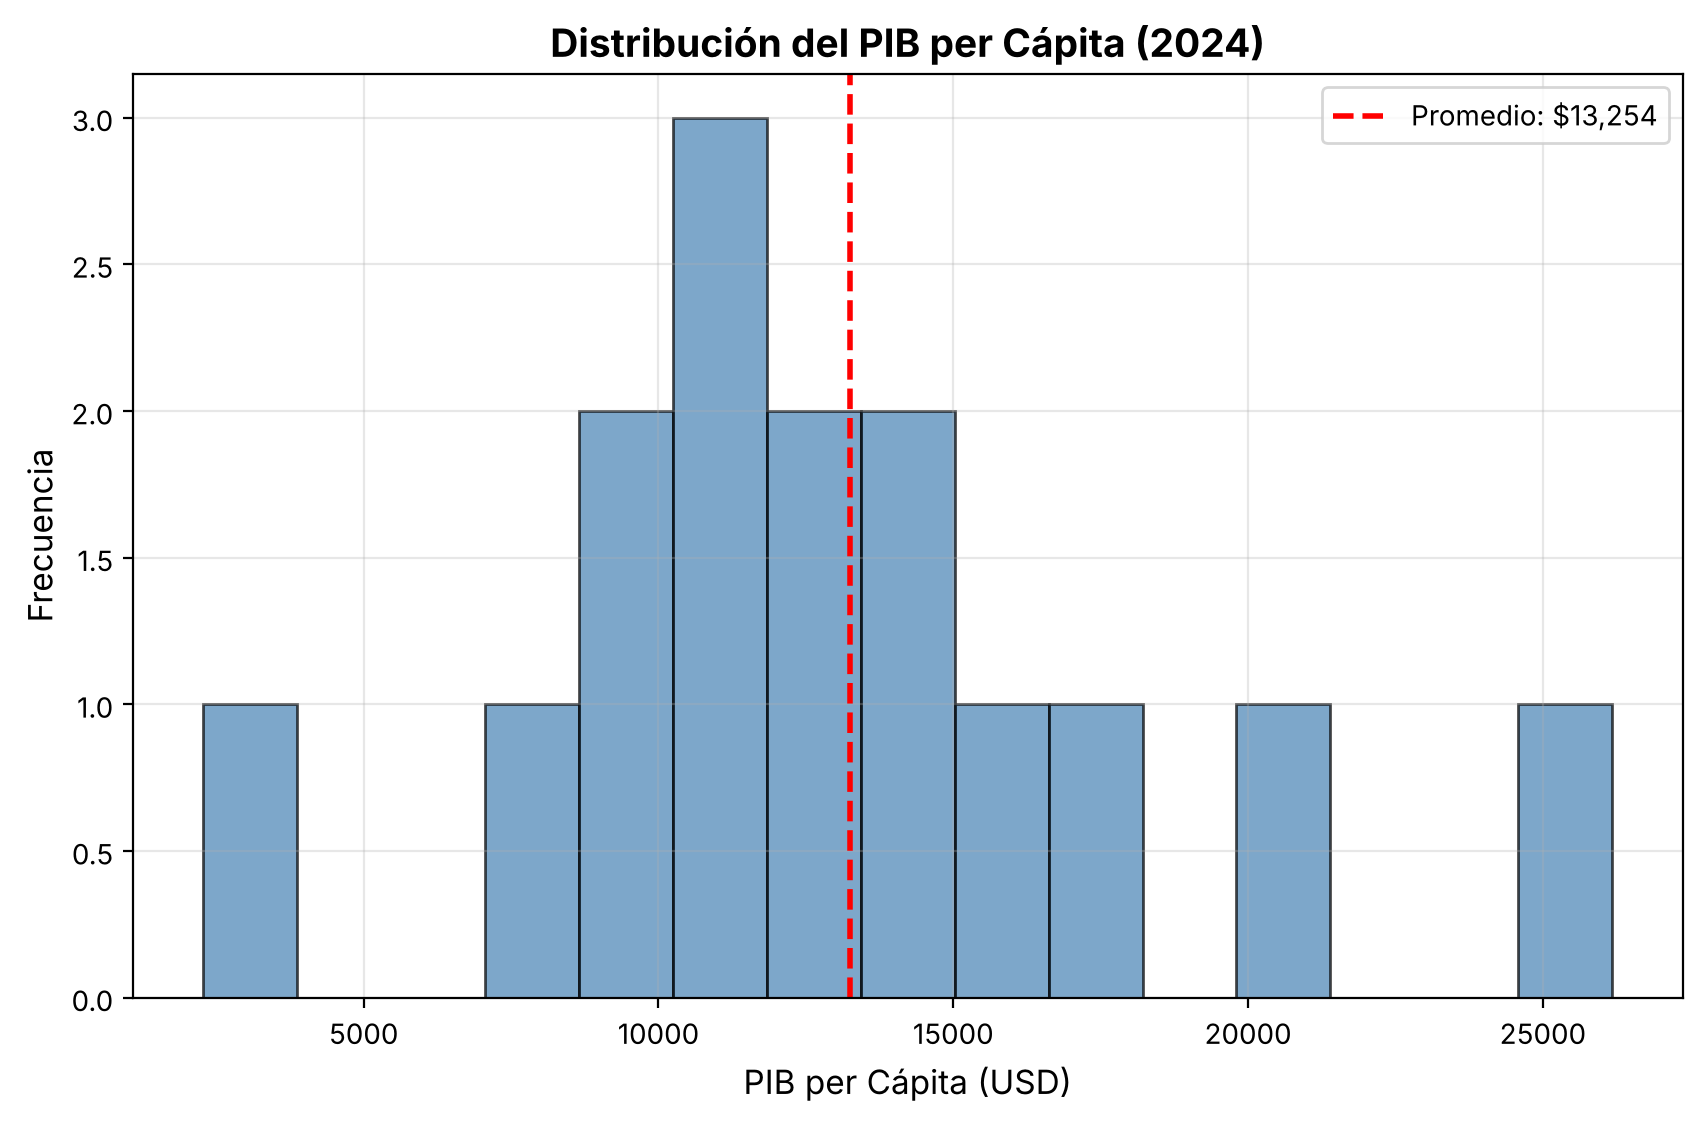

Estadísticas de PIB per Cápita:
count       15.000000
mean     13253.600000
std       5686.213802
min       2277.000000
25%      10156.500000
50%      12381.000000
75%      15477.000000
max      26176.000000
Name: city_gdp/capita, dtype: float64


In [17]:

# Crear histograma para ver la distribución de la economía (city_gdp_capita)
fig, ax = plt.subplots(figsize=(10, 6))

ax.hist(merged['city_gdp/capita'], bins=15, color='steelblue', edgecolor='black', alpha=0.7)

# Obtener promedio
mean_gdp = merged['city_gdp/capita'].mean()
ax.axvline(mean_gdp, color='red', linestyle='--', linewidth=2, label=f'Promedio: ${mean_gdp:,.0f}')

plt.title('Distribución del PIB per Cápita (2024)', fontsize=14, fontweight='bold')
plt.xlabel('PIB per Cápita (USD)', fontsize=12)
plt.ylabel('Frecuencia', fontsize=12)
plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

print(f"Estadísticas de PIB per Cápita:")
print(merged['city_gdp/capita'].describe())


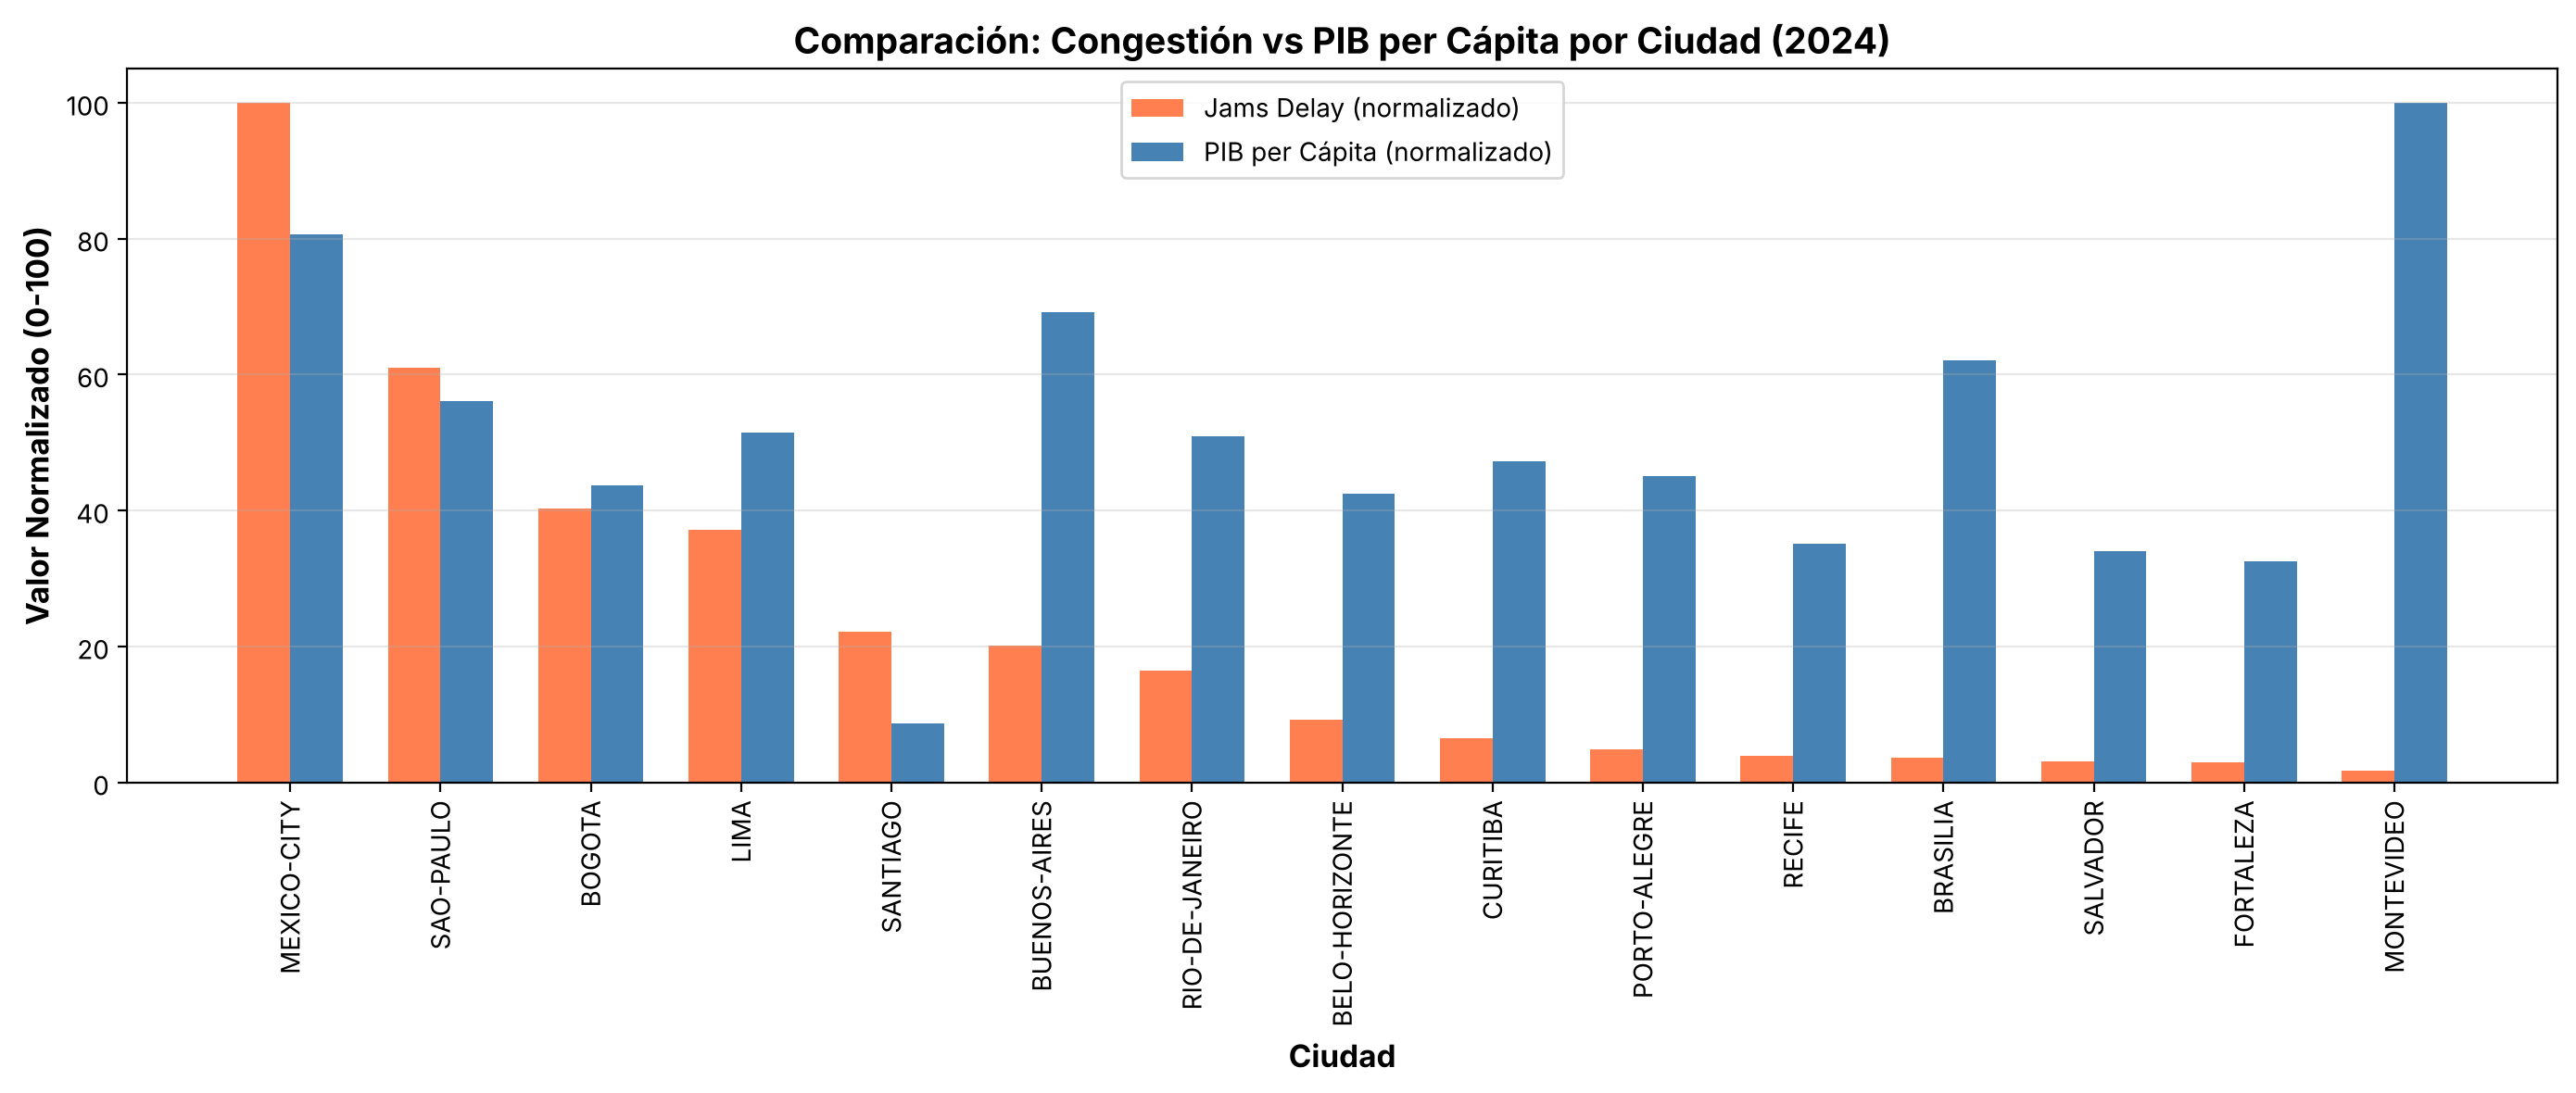

Gráfico generado exitosamente


In [18]:



# Gráfico de barras para comparar jams_delay y city_gdp_capita por ciudad
fig, ax = plt.subplots(figsize=(14, 6))

# Ordenar por jams_delay
merged_sorted = merged.sort_values('jamsdelay', ascending=False)

# Crear gráfico
x = np.arange(len(merged_sorted))
width = 0.35

# Normalizar los valores para que sean comparables
jams_norm = merged_sorted['jamsdelay'] / merged_sorted['jamsdelay'].max() * 100
gdp_norm = merged_sorted['city_gdp/capita'] / merged_sorted['city_gdp/capita'].max() * 100

ax.bar(x - width/2, jams_norm, width, label='Jams Delay (normalizado)', color='coral')
ax.bar(x + width/2, gdp_norm, width, label='PIB per Cápita (normalizado)', color='steelblue')

ax.set_xlabel('Ciudad', fontsize=12, fontweight='bold')
ax.set_ylabel('Valor Normalizado (0-100)', fontsize=12, fontweight='bold')
ax.set_title('Comparación: Congestión vs PIB per Cápita por Ciudad (2024)', fontsize=14, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(merged_sorted['city'].str.upper(), rotation=90)
ax.legend()
ax.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.xticks(rotation=90)
plt.show()

print("Gráfico generado exitosamente")


Correlación con JamsDelay (n = 15 ciudades):
      variable  pearson_r  p_pearson  spearman_rho  p_spearman
PIB per cápita      0.283      0.307         0.207       0.459
     Población      0.879      0.000         0.864       0.000
 Desempleo (%)     -0.687      0.005        -0.488       0.065
         PM2.5      0.768      0.001         0.804       0.000

Sensibilidad: PIB vs JamsDelay sin Santiago (n = 14): r = 0.335, p = 0.242


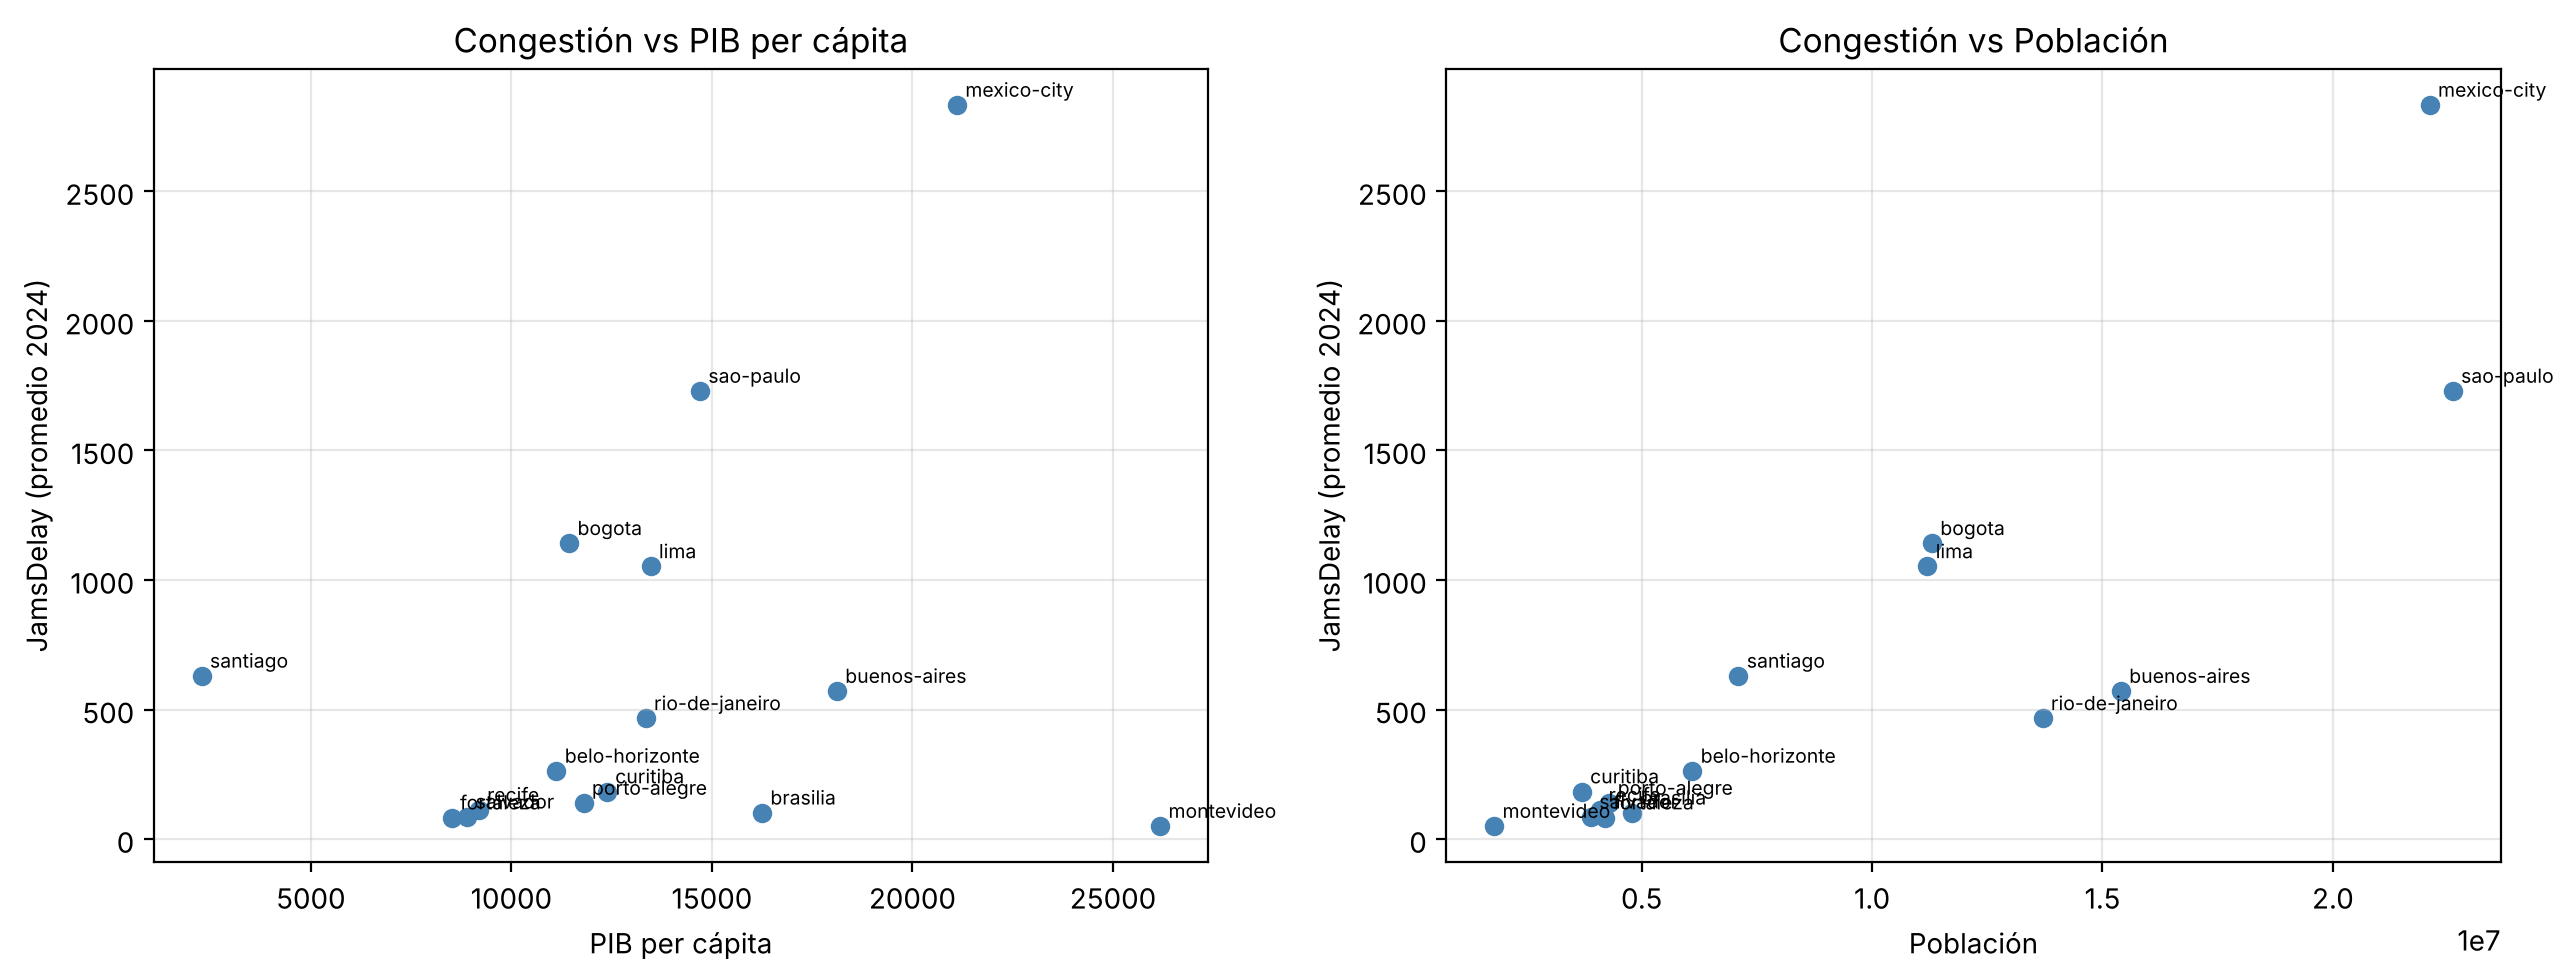

In [19]:
# Análisis de relación: congestión (jamsdelay) vs variables económicas y demográficas (15 ciudades, 2024)
import os
from scipy import stats

variables = {'city_gdp/capita': 'PIB per cápita',
             'population': 'Población',
             'unemployment_%': 'Desempleo (%)',
             'pm2.5_(μg/m³)': 'PM2.5'}

filas = []
for col, nombre in variables.items():
    r, p = stats.pearsonr(merged['jamsdelay'], merged[col])
    rs, ps = stats.spearmanr(merged['jamsdelay'], merged[col])
    filas.append({'variable': nombre, 'pearson_r': r, 'p_pearson': p, 'spearman_rho': rs, 'p_spearman': ps})

tabla_corr = pd.DataFrame(filas).round(3)
print("Correlación con JamsDelay (n = 15 ciudades):")
print(tabla_corr.to_string(index=False))

# Control de calidad: el PIB per cápita de Santiago en 2024 (2,277) es muy bajo frente a 2023 (22,176)
sin_santiago = merged[merged['city'] != 'santiago']
r2, p2 = stats.pearsonr(sin_santiago['jamsdelay'], sin_santiago['city_gdp/capita'])
print(f"\nSensibilidad: PIB vs JamsDelay sin Santiago (n = 14): r = {r2:.3f}, p = {p2:.3f}")

# Gráficos de dispersión
os.makedirs('outputs', exist_ok=True)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (col, nombre) in zip(axes, [('city_gdp/capita', 'PIB per cápita'), ('population', 'Población')]):
    ax.scatter(merged[col], merged['jamsdelay'], color='steelblue')
    for _, f in merged.iterrows():
        ax.annotate(f['city'], (f[col], f['jamsdelay']), fontsize=7, xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel(nombre)
    ax.set_ylabel('JamsDelay (promedio 2024)')
    ax.set_title(f'Congestión vs {nombre}')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/congestion_vs_pib_poblacion.png', dpi=150)
plt.show()


**Lectura de los gráficos y de las correlaciones**

- **PIB per cápita vs congestión:** la relación es débil y no es estadísticamente significativa (Pearson r = 0.28, p = 0.31; Spearman ρ = 0.21, p = 0.46). Las ciudades más ricas no son necesariamente las más congestionadas.
- **Tamaño de la ciudad:** la población es la variable más asociada con la congestión (r = 0.88, p < 0.001). Las megaciudades (Ciudad de México, São Paulo) concentran los mayores retrasos.
- **Otras variables:** PM2.5 (r = 0.77) y desempleo (r = −0.69) también se asocian con la congestión, pero se mueven junto con el tamaño de la ciudad; con solo 15 ciudades no es posible separar sus efectos.
- **Calidad de datos:** el PIB per cápita de Santiago en 2024 (2,277) es inconsistente con su valor de 2023 (22,176), posible error de captura. Sin Santiago la conclusión no cambia (r = 0.34, p = 0.24).


---

## 🧩Paso 7: Exportar y documentar resultados

En esta etapa final consolidarás todo tu trabajo: guardarás el dataset limpio y crearás un resumen que documente los resultados del proyecto.

### 7.1 Guardar dataset final

**🎯Objetivo:**
Generar un CSV limpio, reproducible y con columnas relevantes para análisis posterior.

**Instrucciones**

- Exporta el DataFrame `merged` con el nombre: `ladb_mobility_economy_2024_clean.csv`
- Usa `index=False` para no incluir el índice.


In [20]:

# Exportar el dataset final como CSV
merged.to_csv("ladb_mobility_economy_2024_clean.csv", index=False)

print("✅ Dataset exportado: ladb_mobility_economy_2024_clean.csv")
print(f"\nDimensiones finales: {merged.shape[0]} ciudades × {merged.shape[1]} columnas")
print(f"\nCiudades incluidas:")
print(merged['city'].unique())

✅ Dataset exportado: ladb_mobility_economy_2024_clean.csv

Dimensiones finales: 15 ciudades × 14 columnas

Ciudades incluidas:
<StringArray>
['belo-horizonte',         'bogota',       'brasilia',   'buenos-aires',
       'curitiba',      'fortaleza',           'lima',    'mexico-city',
     'montevideo',   'porto-alegre',         'recife', 'rio-de-janeiro',
       'salvador',       'santiago',      'sao-paulo']
Length: 15, dtype: str


---

# 🧾 Resumen ejecutivo

**Contexto y objetivo:** se evaluó la relación entre la movilidad urbana (congestión, medida con `JamsDelay` de TomTom Traffic Index) y la productividad económica (PIB per cápita, OCDE) en 15 ciudades latinoamericanas durante 2024. Se integraron dos fuentes heterogéneas y se corrigieron formatos de fecha y de números.

**Hallazgos:**
- El PIB per cápita **no** explica de forma significativa la congestión (r = 0.28, p = 0.31).
- El tamaño de la ciudad sí: la población muestra la mayor asociación con el retraso por congestión (r = 0.88, p < 0.001). Ciudad de México y São Paulo lideran la región.
- PM2.5 (r = 0.77) y desempleo (r = −0.69) también se asocian, pero comparten el efecto del tamaño de la ciudad.

**Limitaciones:** muestra de solo 15 ciudades; correlación no implica causalidad; el tráfico se resumió en un promedio anual (no distingue horas ni días); el PIB de Santiago 2024 parece un error de captura en los datos de origen. Además, se corrigió el cruce inicial, que duplicaba cada ciudad al incluir 2023 y 2024.

**Próximos pasos:** analizar la congestión por franja horaria, aplicar un modelo multivariable que controle por población y validar las cifras atípicas con la fuente original.